<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Finding Duplicates Lab**


Estimated time needed: **30** minutes


## Introduction


Data wrangling is a critical step in preparing datasets for analysis, and handling duplicates plays a key role in ensuring data accuracy. In this lab, you will focus on identifying and removing duplicate entries from your dataset. 


## Objectives


In this lab, you will perform the following:


1. Identify duplicate rows in the dataset and analyze their characteristics.
2. Visualize the distribution of duplicates based on key attributes.
3. Remove duplicate values strategically based on specific criteria.
4. Outline the process of verifying and documenting duplicate removal.


## Hands on Lab


Install the needed library


In [112]:
!pip install pandas
!pip install matplotlib

Import pandas module


In [113]:
import pandas as pd
import matplotlib.pyplot as plt

Import matplotlib


## **Load the dataset into a dataframe**


<h2>Read Data</h2>
<p>
We utilize the <code>pandas.read_csv()</code> function for reading CSV files. However, in this version of the lab, which operates on JupyterLite, the dataset needs to be downloaded to the interface using the provided code below.
</p>


In [114]:
# Load the dataset directly from the URL
file_path = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/VYPrOu0Vs3I0hKLLjiPGrA/survey-data-with-duplicate.csv"
df = pd.read_csv(file_path)

# Display the first few rows
df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


Load the data into a pandas dataframe:



Note: If you are working on a local Jupyter environment, you can use the URL directly in the pandas.read_csv() function as shown below:



In [99]:
#df = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv")
#df.head()

## Identify and Analyze Duplicates


### Task 1: Identify Duplicate Rows
1. Count the number of duplicate rows in the dataset.
3. Display the first few duplicate rows to understand their structure.


In [115]:
df.shape

(65457, 114)

In [116]:
# Write your code here
duplicate_count = df.duplicated().sum()
print(f"Number of Duplicate Rows: {duplicate_count}")


Number of Duplicate Rows: 20

In [117]:
df.drop_duplicates(inplace=True)

In [118]:
df.shape

(65437, 114)

In [109]:
df.duplicated().sum()

np.int64(0)

In [106]:
# Write your code here

subset_cols = ['MainBranch', 'Employment', 'RemoteWork']
duplicate_mask = df.duplicated(subset=subset_cols, keep=False)
duplicate_rows = df[duplicate_mask]

### Task 2: Analysis of Duplicate Response Patterns
1. Identify duplicate response patterns based on selected columns such as MainBranch, Employment, and RemoteWork.
2. Clarify that these represent multiple respondents with identical answers rather than duplicate records. Analyse which other columns frequently share identical values within these response-pattern groups.
   


In [119]:
# Select the columns that define the profile pattern
pattern_cols = ['MainBranch', 'Employment', 'RemoteWork']

# Find all rows that share an identical pattern with at least one other row
shared_patterns = df[df.duplicated(subset=pattern_cols, keep=False)]

print(f"Total rows sharing identical profile patterns: {len(shared_patterns)}")
print(f"Number of unique profile combinations: {df[pattern_cols].drop_duplicates().shape[0]}")

Total rows sharing identical profile patterns: 65270
Number of unique profile combinations: 561

In [121]:
# Group by the patterns and see which other columns remain identical or highly similar
# Let's see the most common combination of MainBranch, Employment, o RemoteWork
most_common_pattern = df.groupby(pattern_cols).size().idxmax()
print(f"Most common profile pattern: {most_common_pattern}\n")

# Filter the data frame for just this specific group of respondents
respondent_group = df[
    (df['MainBranch'] == most_common_pattern[0]) &
    (df['Employment'] == most_common_pattern[1]) &
    (df['RemoteWork'] == most_common_pattern[2])
]

# Analyze which other columns frequently have the exact same answer within this group
print("Top 10 columns with the least variation (most frequent identical values) in this group:")
for col in df.columns:
    if col not in pattern_cols:
        # Calculate what percentage of this group give the exact same top answer
        top_value_pct = respondent_group[col].value_counts(normalize=True).max() * 100
        if top_value_pct > 70: # Adjust threshold as needed (e.g., columns where > 70% match) 
            print(f"- {col}: {top_value_pct:.1f}% of respondents gave the identical answer")

Most common profile pattern: ('I am a developer by profession', 'Employed, full-time', 'Hybrid (some remote, some in-person)')

Top 10 columns with the least variation (most frequent identical values) in this group:
- Check: 100.0% of respondents gave the identical answer- SOAccount: 78.4% of respondents gave the identical answer
- AIThreat: 71.0% of respondents gave the identical answer
- ICorPM: 87.7% of respondents gave the identical answer

In [123]:
employment_mode = df['Employment'].mode()[0]
df['Employment'].fillna(employment_mode, inplace = False)

0        Employed, full-time
1        Employed, full-time
2        Employed, full-time
3         Student, full-time
4         Student, full-time
                ...         
65432    Employed, full-time
65433    Employed, full-time
65434    Employed, full-time
65435    Employed, full-time
65436     Student, full-time
Name: Employment, Length: 65437, dtype: str

In [124]:
subset_cols = ['MainBranch', 'Employment', 'RemoteWork']
duplicate_mask = df.duplicated(subset=subset_cols, keep=False)
duplicate_row = df[duplicate_mask]

### Task 3: Visualize Shared Response Patterns
1. Create visualizations to show the distribution of shared response patterns across different categories.
2. Use bar charts or pie charts to represent the distribution of respondents who share identical values for MainBranch, Employment, and RemoteWork, grouped by Country and Employment.


IndexError: index 0 is out of bounds for axis 0 with size 0

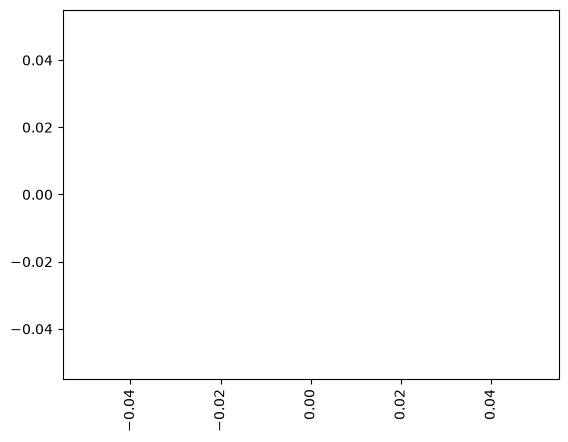

In [95]:
## Write your code here
duplicate_rows = df[df.duplicated(keep=False)]
country_counts = duplicate_rows['Country'].value_counts()
employment_counts = duplicate_rows['Employment'].value_counts()

country_counts.plot(kind='bar')
plt.title('Duplicates by Country')
plt.ylabel('Duplicate counts')
plt.xlabel('Country')
plt.xticks(rotation = 80)
plt.show()

ValueError: All wedge sizes are zero

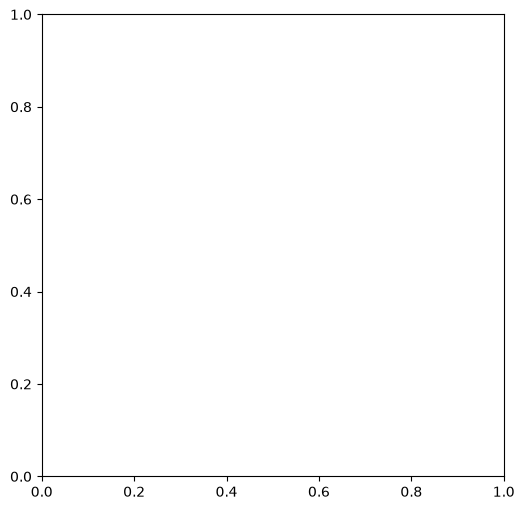

In [82]:
plt.figure(figsize = (8, 6))
employment_counts.plot(kind='pie', autopct='%1.1f%%')
plt.title('Duplicate Entries by Employment Type')
plt.ylabel('')
plt.tight_layout()
plt.show()

IndexError: index 0 is out of bounds for axis 0 with size 0

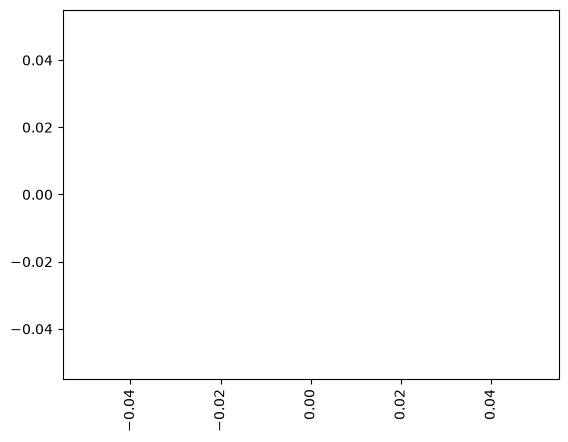

In [83]:

employment_counts.plot (kind = 'bar')
plt.title('Duplicate by Employment Type')
plt.ylabel('Duplicate counts')
plt.xlabel('Employment Type')
plt.xticks(rotation = 75)
plt.show()

### Task 4: Evaluate Duplicate Handling Strategy
1. Analyse the dataset to determine which column(s) define record uniqueness.
2. Assess whether removing rows based on a subset of columns (rather than complete row duplication) is appropriate.
Justify your decision with reference to the structure and purpose of the dataset.


## Verify and Document Duplicate Removal Process


### Task 5: Documentation
1. Document the process of identifying and removing duplicates.


2. Explain the reasoning behind selecting specific columns for identifying and removing duplicates.


### Summary and Next Steps
**In this lab, you focused on identifying and analyzing duplicate rows within the dataset.**

- You employed various techniques to explore the nature of duplicates and applied strategic methods for their removal.
- For additional analysis, consider investigating the impact of duplicates on specific analyses and how their removal affects the results.
- This version of the lab is more focused on duplicate analysis and handling, providing a structured approach to deal with duplicates in a dataset effectively.


<!--
## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|
|2024-11- 05|1.3|Madhusudhan Moole|Updated lab|
|2024-10-28|1.2|Madhusudhan Moole|Updated lab|
|2024-09-24|1.1|Madhusudhan Moole|Updated lab|
|2024-09-23|1.0|Raghul Ramesh|Created lab|
--!>


Copyright © IBM Corporation. All rights reserved.
